In [ ]:
!pip install -q medmnist torchmetrics seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.3 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassF1Score,
    MulticlassAUROC,
    MulticlassConfusionMatrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import medmnist
from medmnist import INFO

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
#dataset
data_flag = 'bloodmnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])
num_classes = len(info['label'])

#normalization
train_transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((224,224)),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomRotation(10),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((224,224)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


Dataclass: <class 'medmnist.dataset.BloodMNIST'>


In [ ]:
#splitting dataset into train, validation and test set
train_dataset = DataClass(split='train', transform=train_transform, download=True)
val_dataset = DataClass(split='val', transform=test_transform, download=True)
test_dataset = DataClass(split='test', transform=test_transform, download=True)

train_loader = DataLoader(train_dataset, batch_size= 32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size= 32)
test_loader = DataLoader(test_dataset, batch_size= 32)



In [ ]:
# len(train_loader), len(val_dataset), len(test_dataset)

(374, 1712, 3421)

In [ ]:
# train_dataset.imgs.shape, val_dataset.imgs.shape, test_dataset.imgs.shape

((11959, 28, 28, 3), (1712, 28, 28, 3), (3421, 28, 28, 3))

In [ ]:
# train_dataset.labels.shape, val_dataset.labels.shape, test_dataset.labels.shape

((11959, 1), (1712, 1), (3421, 1))

In [ ]:
# train_dataset[0][0].shape, train_dataset.imgs.ndim

(torch.Size([3, 224, 224]), 4)

In [ ]:
#model
model = torchvision.models.resnet18(weights= torchvision.models.ResNet18_Weights.DEFAULT)

#freezing backbone
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
#changing classifier
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

In [ ]:
model.load_state_dict(torch.load(f='models/bloodMnist_model_adam.pth'))

<All keys matched successfully>

In [ ]:
#loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam( filter(lambda p: p.requires_grad, model.parameters()), lr=0.0003 )

In [ ]:
#training
epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
      images = images.to(device)
      labels = labels.squeeze().long().to(device)
      optimizer.zero_grad()
      outputs = model(images)
      loss = loss_fn(outputs, labels)
      loss.backward()
      optimizer.step()

      running_loss += loss.item()
      # print(f"running loss: {running_loss}")
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/10] Loss: 0.4329
Epoch [2/10] Loss: 0.2191
Epoch [3/10] Loss: 0.1778
Epoch [4/10] Loss: 0.1382
Epoch [5/10] Loss: 0.1296
Epoch [6/10] Loss: 0.1194
Epoch [7/10] Loss: 0.1086
Epoch [8/10] Loss: 0.0911
Epoch [9/10] Loss: 0.0868
Epoch [10/10] Loss: 0.0826


In [ ]:
from pathlib import Path

MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "bloodMnist_model_adam.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model.state_dict(), # only saving the state_dict() only saves the models learned parameters
           f=MODEL_SAVE_PATH)


Saving model to: models/bloodMnist_model_adam.pth


In [ ]:
#metrics
accuracy = MulticlassAccuracy(num_classes=num_classes).to(device)
precision = MulticlassPrecision(num_classes=num_classes, average="macro").to(device)
recall = MulticlassRecall(num_classes=num_classes, average="macro").to(device)
f1 = MulticlassF1Score(num_classes=num_classes, average="macro").to(device)
auroc = MulticlassAUROC(num_classes=num_classes).to(device)
confmat_metric = MulticlassConfusionMatrix(num_classes=num_classes).to(device)


In [ ]:
#validation
model.eval()

all_preds = []
all_targets = []
all_probs = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.squeeze().to(device)
        # print(f"labels: {labels}")

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        all_preds.append(preds)
        all_targets.append(labels)
        all_probs.append(probs)

all_preds = torch.cat(all_preds)
all_targets = torch.cat(all_targets)
all_probs = torch.cat(all_probs)


In [ ]:
print("Validation Metrics")
print("Accuracy :", accuracy(all_preds, all_targets).item())
print("Precision:", precision(all_preds, all_targets).item())
print("Recall   :", recall(all_preds, all_targets).item())
print("F1 Score :", f1(all_preds, all_targets).item())
print("AUROC    :", auroc(all_probs, all_targets).item())


Validation Metrics
Accuracy : 0.9434918165206909
Precision: 0.9290716648101807
Recall   : 0.9434918165206909
F1 Score : 0.9330376386642456
AUROC    : 0.9977582693099976


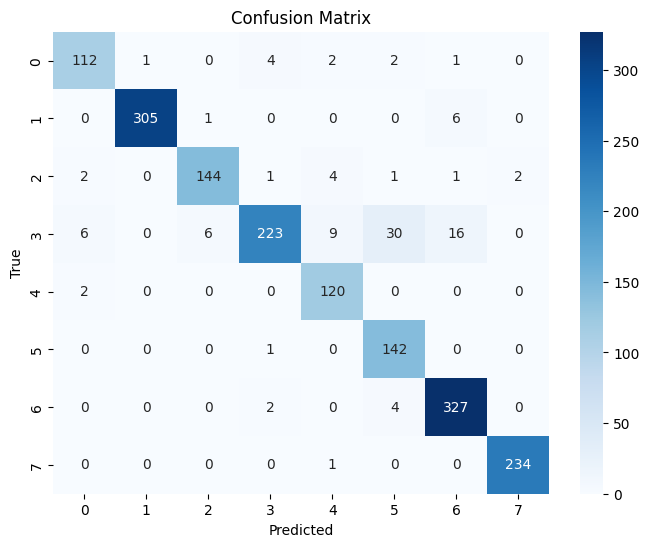

In [ ]:
#confusion matrix
confmat = confmat_metric(all_preds, all_targets)

plt.figure(figsize=(8,6))
sns.heatmap(confmat.cpu().numpy(), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
#test
model.eval()

all_preds = []
all_targets = []
all_probs = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.squeeze().to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)

        all_preds.append(preds)
        all_targets.append(labels)
        all_probs.append(probs)

all_preds = torch.cat(all_preds)
all_targets = torch.cat(all_targets)
all_probs = torch.cat(all_probs)


In [ ]:
print("Test Metrics")
print("Accuracy :", accuracy(all_preds, all_targets).item())
print("Precision:", precision(all_preds, all_targets).item())
print("Recall   :", recall(all_preds, all_targets).item())
print("F1 Score :", f1(all_preds, all_targets).item())
print("AUROC    :", auroc(all_probs, all_targets).item())

Test Metrics
Accuracy : 0.94193434715271
Precision: 0.9302698373794556
Recall   : 0.94193434715271
F1 Score : 0.934273362159729
AUROC    : 0.9968371987342834


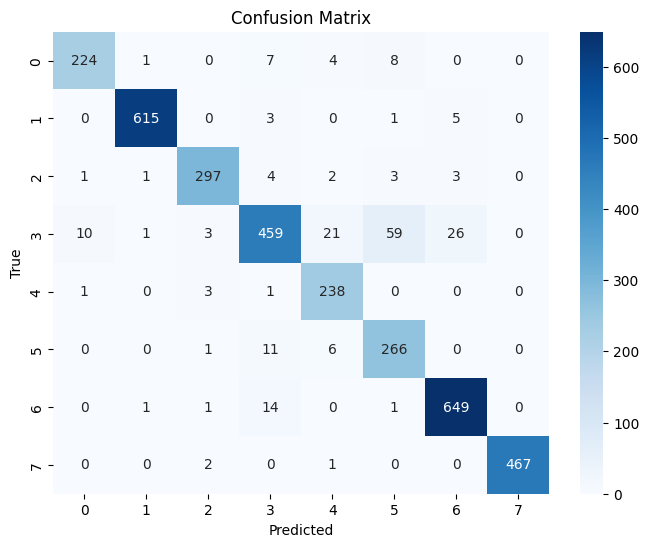

In [ ]:
#confusion matrix
confmat = confmat_metric(all_preds, all_targets)

plt.figure(figsize=(8,6))
sns.heatmap(confmat.cpu().numpy(), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

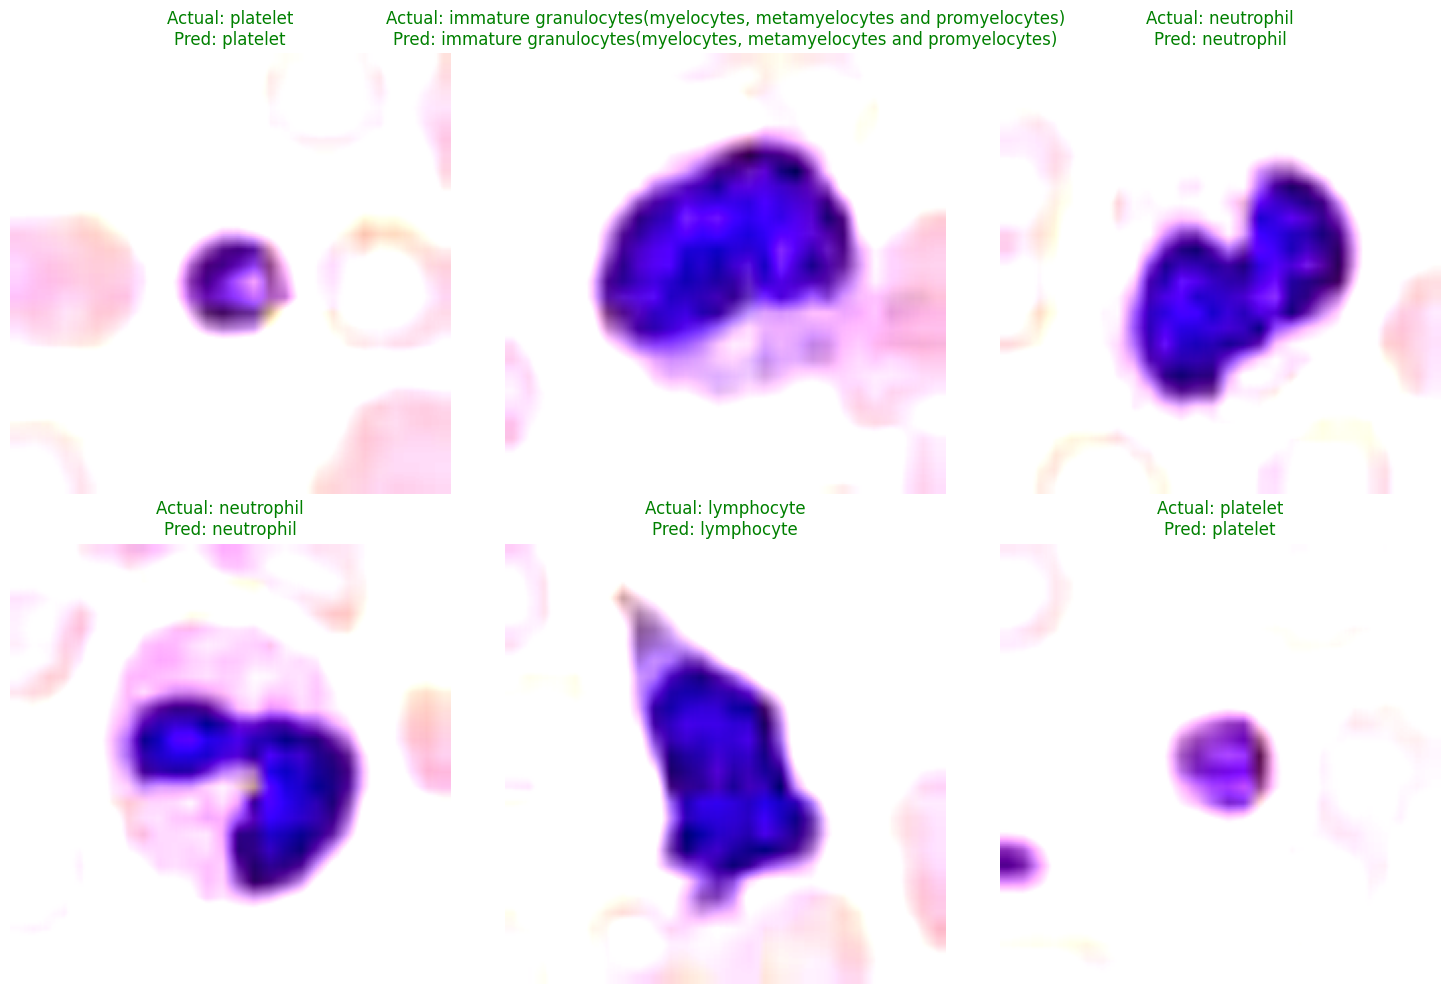

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Map the numeric labels back to their medical names
classes = info['label']

def visualize_results(model, dataset, num_samples=6):
    model.eval()
    fig = plt.figure(figsize=(15, 10))

    # Get random indices
    indices = np.random.choice(len(dataset), num_samples, replace=False)

    with torch.no_grad():
        for i, idx in enumerate(indices):
            image, label = dataset[idx]

            # Prepare image for model (add batch dimension and move to GPU)
            input_tensor = image.unsqueeze(0).to(device)
            output = model(input_tensor)

            # Get prediction
            _, pred = torch.max(output, 1)

            # Convert image back to displayable format (un-normalize)
            image_display = image.permute(1, 2, 0).numpy()
            image_display = (image_display * 0.5) + 0.5 # Reverse the Normalize([0.5], [0.5])

            ax = fig.add_subplot(2, 3, i + 1)
            ax.imshow(np.clip(image_display, 0, 1))

            actual_name = classes[str(label[0])]
            pred_name = classes[str(pred.item())]

            color = 'green' if actual_name == pred_name else 'red'
            ax.set_title(f"Actual: {actual_name}\nPred: {pred_name}", color=color)
            ax.axis('off')

    plt.tight_layout()
    plt.show()

# Run the visualization
visualize_results(model, test_dataset)